In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import os

print("Tudo importado!")

Tudo importado!


In [2]:
# Caminho base onde estão as pastas dos sets
caminho_base = "."  # o notebook está na mesma pasta que F, N, O, S, Z

# Mapeamento: pasta → nome do set → rótulo numérico
sets = {
    "Z": {"nome": "Set A - Saudável (olhos abertos)", "rotulo": 0},
    "O": {"nome": "Set B - Saudável (olhos fechados)", "rotulo": 0},
    "S": {"nome": "Set E - Crise epiléptica (ictal)", "rotulo": 1},
}

sinais = []
rotulos = []
origens = []  # guarda de qual set cada sinal veio, para análise depois

for pasta, info in sets.items():
    caminho_pasta = os.path.join(caminho_base, pasta)
    arquivos = sorted([f for f in os.listdir(caminho_pasta) if f.lower().endswith('.txt')])
    
    for arquivo in arquivos:
        caminho_arquivo = os.path.join(caminho_pasta, arquivo)
        sinal = np.loadtxt(caminho_arquivo)
        sinais.append(sinal)
        rotulos.append(info["rotulo"])
        origens.append(info["nome"])

sinais = np.array(sinais, dtype=np.float32)
rotulos = np.array(rotulos, dtype=np.int64)

print(f"Total de sinais carregados: {len(sinais)}")
print(f"Formato de cada sinal: {sinais[0].shape}")
print(f"Taxa de amostragem: 173.61 Hz")
print(f"Duração de cada sinal: {sinais[0].shape[0] / 173.61:.1f} segundos")
print(f"\nDistribuição das classes:")
print(f"  Classe 0 (saudável): {(rotulos == 0).sum()} sinais")
print(f"  Classe 1 (crise):    {(rotulos == 1).sum()} sinais")

Total de sinais carregados: 300
Formato de cada sinal: (4097,)
Taxa de amostragem: 173.61 Hz
Duração de cada sinal: 23.6 segundos

Distribuição das classes:
  Classe 0 (saudável): 200 sinais
  Classe 1 (crise):    100 sinais


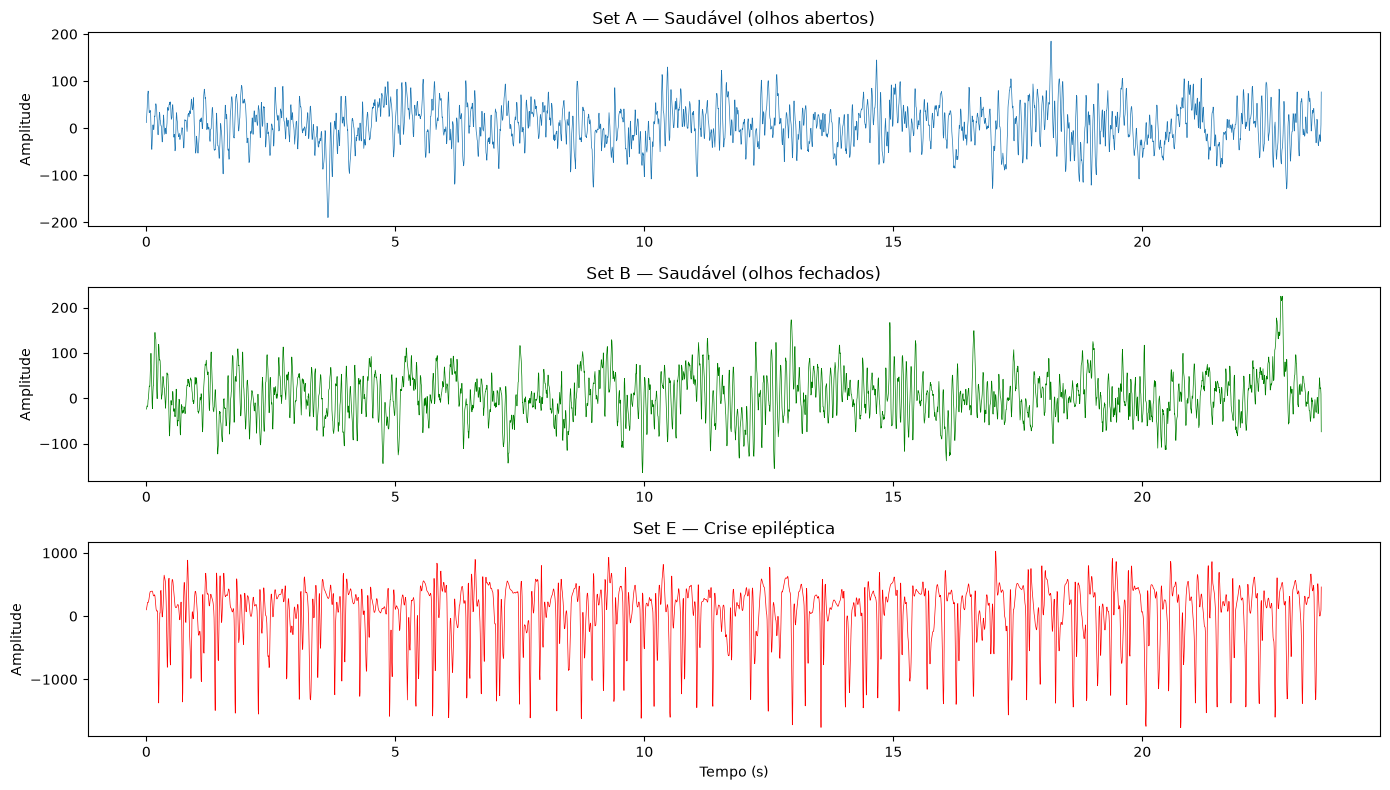

In [3]:
# Eixo de tempo para os 4096 pontos a 173.61 Hz
t_eeg = np.arange(4097) / 173.61

fig, eixos = plt.subplots(3, 1, figsize=(14, 8))

# Um sinal saudável com olhos abertos (set A)
eixos[0].plot(t_eeg, sinais[0], linewidth=0.5)
eixos[0].set_title("Set A — Saudável (olhos abertos)")
eixos[0].set_ylabel("Amplitude")

# Um sinal saudável com olhos fechados (set B)
eixos[1].plot(t_eeg, sinais[100], linewidth=0.5, color='green')
eixos[1].set_title("Set B — Saudável (olhos fechados)")
eixos[1].set_ylabel("Amplitude")

# Um sinal de crise (set E)
eixos[2].plot(t_eeg, sinais[200], linewidth=0.5, color='red')
eixos[2].set_title("Set E — Crise epiléptica")
eixos[2].set_ylabel("Amplitude")
eixos[2].set_xlabel("Tempo (s)")

plt.tight_layout()
plt.show()

In [4]:
# Configuração da segmentação
duracao_janela = 1.0  # segundos
taxa = 173.61         # Hz
pontos_por_janela = int(duracao_janela * taxa)  # 173 pontos por janela

print(f"Duração da janela: {duracao_janela} s")
print(f"Pontos por janela: {pontos_por_janela}")

# Segmenta cada sinal longo em várias janelas
janelas = []
rotulos_janelas = []

for i in range(len(sinais)):
    sinal = sinais[i]
    rotulo = rotulos[i]
    
    # Quantas janelas inteiras cabem nesse sinal
    num_janelas = len(sinal) // pontos_por_janela
    
    for j in range(num_janelas):
        inicio = j * pontos_por_janela
        fim = inicio + pontos_por_janela
        janela = sinal[inicio:fim]
        janelas.append(janela)
        rotulos_janelas.append(rotulo)

janelas = np.array(janelas, dtype=np.float32)
rotulos_janelas = np.array(rotulos_janelas, dtype=np.int64)

print(f"\nTotal de janelas: {len(janelas)}")
print(f"Formato de cada janela: {janelas[0].shape}")
print(f"Classe 0 (saudável): {(rotulos_janelas == 0).sum()} janelas")
print(f"Classe 1 (crise):    {(rotulos_janelas == 1).sum()} janelas")

Duração da janela: 1.0 s
Pontos por janela: 173

Total de janelas: 6900
Formato de cada janela: (173,)
Classe 0 (saudável): 4600 janelas
Classe 1 (crise):    2300 janelas


In [5]:
janelas_treino, janelas_teste, rot_treino, rot_teste = train_test_split(
    janelas, rotulos_janelas, test_size=0.2, random_state=42, stratify=rotulos_janelas
)

print(f"Treino: {len(janelas_treino)} janelas")
print(f"Teste:  {len(janelas_teste)} janelas")
print(f"\nTreino — Classe 0: {(rot_treino == 0).sum()}, Classe 1: {(rot_treino == 1).sum()}")
print(f"Teste  — Classe 0: {(rot_teste == 0).sum()}, Classe 1: {(rot_teste == 1).sum()}")

Treino: 5520 janelas
Teste:  1380 janelas

Treino — Classe 0: 3680, Classe 1: 1840
Teste  — Classe 0: 920, Classe 1: 460


In [6]:
media_treino = janelas_treino.mean()
desvio_treino = janelas_treino.std()

janelas_treino_norm = (janelas_treino - media_treino) / desvio_treino
janelas_teste_norm = (janelas_teste - media_treino) / desvio_treino

print(f"Média do treino: {media_treino:.4f}")
print(f"Desvio padrão: {desvio_treino:.4f}")
print(f"\nApós normalização:")
print(f"  Treino — média: {janelas_treino_norm.mean():.4f}, desvio: {janelas_treino_norm.std():.4f}")
print(f"  Teste  — média: {janelas_teste_norm.mean():.4f}, desvio: {janelas_teste_norm.std():.4f}")

Média do treino: -7.4134
Desvio padrão: 204.2511

Após normalização:
  Treino — média: 0.0000, desvio: 1.0000
  Teste  — média: -0.0092, desvio: 0.9775


In [7]:
# Converter para tensores
X_treino = torch.FloatTensor(janelas_treino_norm).unsqueeze(1)  # adiciona canal
y_treino = torch.LongTensor(rot_treino)
X_teste = torch.FloatTensor(janelas_teste_norm).unsqueeze(1)
y_teste = torch.LongTensor(rot_teste)

print(f"X_treino: {X_treino.shape}  (batch, canal, pontos)")
print(f"X_teste:  {X_teste.shape}")

# DataLoaders
dataset_treino = TensorDataset(X_treino, y_treino)
dataset_teste = TensorDataset(X_teste, y_teste)

loader_treino = DataLoader(dataset_treino, batch_size=64, shuffle=True)
loader_teste = DataLoader(dataset_teste, batch_size=64, shuffle=False)

print(f"\nBatches de treino: {len(loader_treino)}")
print(f"Batches de teste: {len(loader_teste)}")

X_treino: torch.Size([5520, 1, 173])  (batch, canal, pontos)
X_teste:  torch.Size([1380, 1, 173])

Batches de treino: 87
Batches de teste: 22


In [8]:
class CNN1D_EEG(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Parte convolucional
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=16, kernel_size=7, padding=3)
        self.pool = nn.MaxPool1d(kernel_size=2)
        self.conv2 = nn.Conv1d(in_channels=16, out_channels=32, kernel_size=5, padding=2)
        
        # Truque: descobre o tamanho depois do achatamento automaticamente
        # Passa um tensor fictício pelas convoluções para ver o tamanho que sai
        with torch.no_grad():
            ficticio = torch.zeros(1, 1, 173)  # 1 amostra, 1 canal, 173 pontos
            ficticio = self.pool(self.conv1(ficticio))
            ficticio = self.pool(self.conv2(ficticio))
            tamanho_achatado = ficticio.view(1, -1).shape[1]
        
        print(f"Tamanho após achatamento: {tamanho_achatado}")
        
        # Parte densa
        self.fc1 = nn.Linear(tamanho_achatado, 64)
        self.fc2 = nn.Linear(64, 2)  # 2 classes: saudável vs crise
        
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)
    
    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

modelo = CNN1D_EEG()
print(modelo)
total_params = sum(p.numel() for p in modelo.parameters())
print(f"\nTotal de parâmetros: {total_params:,}")

Tamanho após achatamento: 1376
CNN1D_EEG(
  (conv1): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
  (fc1): Linear(in_features=1376, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)

Total de parâmetros: 90,978


In [9]:
criterio = nn.CrossEntropyLoss()
otimizador = optim.Adam(modelo.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(otimizador, step_size=5, gamma=0.5)

num_epocas = 20

for epoca in range(num_epocas):
    modelo.train()
    perda_acumulada = 0.0
    acertos = 0
    total = 0
    
    for entradas, rotulos_batch in loader_treino:
        otimizador.zero_grad()
        saidas = modelo(entradas)
        perda = criterio(saidas, rotulos_batch)
        perda.backward()
        otimizador.step()
        
        perda_acumulada += perda.item()
        _, previstos = saidas.max(1)
        acertos += (previstos == rotulos_batch).sum().item()
        total += rotulos_batch.size(0)
    
    scheduler.step()
    lr_atual = otimizador.param_groups[0]['lr']
    perda_media = perda_acumulada / len(loader_treino)
    acuracia = 100 * acertos / total
    print(f"Época {epoca+1}/{num_epocas} — Perda: {perda_media:.4f} — Acurácia: {acuracia:.2f}% — LR: {lr_atual:.6f}")

print("\nTreinamento concluído!")

Época 1/20 — Perda: 0.1295 — Acurácia: 95.63% — LR: 0.001000
Época 2/20 — Perda: 0.0702 — Acurácia: 97.39% — LR: 0.001000
Época 3/20 — Perda: 0.0542 — Acurácia: 97.90% — LR: 0.001000
Época 4/20 — Perda: 0.0456 — Acurácia: 98.39% — LR: 0.001000
Época 5/20 — Perda: 0.0328 — Acurácia: 98.84% — LR: 0.000500
Época 6/20 — Perda: 0.0257 — Acurácia: 99.24% — LR: 0.000500
Época 7/20 — Perda: 0.0226 — Acurácia: 99.20% — LR: 0.000500
Época 8/20 — Perda: 0.0179 — Acurácia: 99.42% — LR: 0.000500
Época 9/20 — Perda: 0.0161 — Acurácia: 99.49% — LR: 0.000500
Época 10/20 — Perda: 0.0152 — Acurácia: 99.53% — LR: 0.000250
Época 11/20 — Perda: 0.0114 — Acurácia: 99.69% — LR: 0.000250
Época 12/20 — Perda: 0.0109 — Acurácia: 99.64% — LR: 0.000250
Época 13/20 — Perda: 0.0115 — Acurácia: 99.60% — LR: 0.000250
Época 14/20 — Perda: 0.0097 — Acurácia: 99.80% — LR: 0.000250
Época 15/20 — Perda: 0.0106 — Acurácia: 99.67% — LR: 0.000125
Época 16/20 — Perda: 0.0081 — Acurácia: 99.80% — LR: 0.000125
Época 17/20 — Per

In [10]:
modelo.eval()
acertos = 0
total = 0

with torch.no_grad():
    for entradas, rotulos_batch in loader_teste:
        saidas = modelo(entradas)
        _, previstos = saidas.max(1)
        acertos += (previstos == rotulos_batch).sum().item()
        total += rotulos_batch.size(0)

acuracia_teste = 100 * acertos / total
print(f"Acurácia no teste: {acuracia_teste:.2f}%")
print(f"Acertos: {acertos}/{total}")

Acurácia no teste: 99.13%
Acertos: 1368/1380
